# Notebook 2: Model Training and Tuning

**Project:** Luxury Watch Resale Price Analysis (final capstone)
**Author:** Mina Andrawos

This notebook trains five types of regression models on Dataset 1 (about 260,000 listings) to predict resale price, tunes each with cross-validated grid search, and measures how much each group of features (watch attributes, brand, model line) adds to the prediction.

| # | Notebook | Purpose |
|---|---|---|
| 1 | [Data cleaning and EDA](01_data_cleaning_and_eda.ipynb) | Clean both datasets, engineer features, explore price drivers |
| **2** | **Model training and tuning (this notebook)** | Compare five model types with cross-validation and grid search |
| 3 | [Model evaluation and insights](03_model_evaluation_and_insights.ipynb) | Test-set results, error analysis, feature importance, price premiums |
| 4 | [Box, papers and seller analysis](04_box_papers_and_seller_analysis.ipynb) | Measure the value of box, papers and seller reputation |

### Notebook outline
1. Setup and data
2. Evaluation metric and validation strategy
3. Features and preprocessing
4. Hyperparameter tuning with grid search (5 model types)
5. Model comparison on the tuning sample
6. Which features matter? Full-training-set cross-validation and final model selection
7. Hold-out test set: final check
8. Saving the selected model
9. Summary

## 1. Setup and Data

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from threadpoolctl import threadpool_limits

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")

# Gradient boosting runs much faster here with one OpenMP thread per model; the speed-up comes
# instead from running cross-validation folds in parallel (n_jobs=-1)
threadpool_limits(limits=1, user_api="openmp")
# Harmless notice from the parallel backend when it recycles a worker process
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")

RANDOM_STATE = 42
PROCESSED_DIR = Path("data/processed")
MODELS_DIR = Path("models")
IMAGES_DIR = Path("images")
MODELS_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

listings = pd.read_parquet(PROCESSED_DIR / "listings_clean.parquet")
print(f"Listings: {listings.shape[0]:,} rows, {listings.shape[1]} columns")

Listings: 260,648 rows, 23 columns


## 2. Evaluation Metric and Validation Strategy

**Target:** `log_price` = log10(price). Notebook 1 showed price is extremely right-skewed; on the log scale errors are *relative*, which matches the way prices are usually compared (in percentages, e.g. "10% too expensive"), and a few six-figure watches do not dominate the fit.

**Primary metric: RMSE on log10 price** (lower is better), used to tune and select models.
- It is in the same units as the target, and it can be translated into plain terms: `10 ** RMSE` is a typical *error factor* (e.g. 1.5 = typically off by about 1.5x).
- It squares errors, so it penalizes **large mispricings** more than small ones. For a buyer, seller or platform, a watch valued at half or twice its worth is far more costly than one that is 5% off.

**Supporting metrics:**
- **R² on log price**: share of variation in log price explained (1 = perfect, 0 = no better than predicting the average). Reported because the initial report used it (Ridge baseline R² = 0.80 on Dataset 2).
- **Median absolute percentage error (MdAPE)** in dollars: "the typical prediction is X% away from the listed price". The median is used so a few extreme listings do not dominate.
- **Share of predictions within ±25%** of the listed price: a practical "is this good enough to price a watch?" measure.

**Validation strategy:**
- **20% of listings are held out as a test set** and used only once, at the end (section 7).
- On the remaining 80% (training set), every model is tuned with **5-fold cross-validation** inside `GridSearchCV`: the training data is split into 5 parts, each model is trained on 4 parts and scored on the 5th, five times, and the scores are averaged.
- **Grid search runs on a random sample of 40,000 training listings.** Running all parameter combinations (270 Random Forest and Gradient Boosting fits) on all 208,000 training rows would take several times longer. The assumption that 40,000 rows are enough to rank the settings is checked in section 6, where the tuned models are cross-validated on the full training set and keep the same ranking. All models are tuned on the *same* sample with the *same* folds, so their scores are directly comparable. The chosen settings are then re-trained on the full training set.

In [2]:
train_df, test_df = train_test_split(listings, test_size=0.2, random_state=RANDOM_STATE)
tuning_df = train_df.sample(n=40_000, random_state=RANDOM_STATE)
cv_folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Training set: {len(train_df):,} listings | Test set: {len(test_df):,} | Tuning sample: {len(tuning_df):,}")
print(f"Median price - training: ${train_df['price'].median():,.0f}, test: ${test_df['price'].median():,.0f}")


def regression_metrics(y_true_log, y_pred_log):
    """All evaluation metrics for predictions on the log10 scale."""
    actual_usd, predicted_usd = 10 ** np.asarray(y_true_log), 10 ** np.asarray(y_pred_log)
    abs_pct_error = np.abs(predicted_usd - actual_usd) / actual_usd
    return {
        "RMSE (log10)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "R² (log)": r2_score(y_true_log, y_pred_log),
        "MAE (log10)": mean_absolute_error(y_true_log, y_pred_log),
        "MdAPE": np.median(abs_pct_error),
        "Within ±25%": np.mean(abs_pct_error <= 0.25),
        "Median abs error (USD)": np.median(np.abs(predicted_usd - actual_usd)),
    }


metric_formats = {"RMSE (log10)": "{:.3f}", "R² (log)": "{:.3f}", "MAE (log10)": "{:.3f}", "MdAPE": "{:.1%}",
                  "Within ±25%": "{:.1%}", "Median abs error (USD)": "${:,.0f}", "Error factor": "{:.2f}x"}

Training set: 208,518 listings | Test set: 52,130 | Tuning sample: 40,000
Median price - training: $6,760, test: $6,821


**Result:** the training and test sets have very similar median prices, consistent with a representative random split.

## 3. Features and Preprocessing
Three nested **feature sets** are defined to answer the research question ("which *combination* of features matters?"):

| Set | Features | Question it answers |
|---|---|---|
| **A: Attributes** | movement, case & bracelet material, condition, gender, case size, age, approximate-year flag, 8 text flags (complications, diamonds, limited edition) | How far can physical attributes alone go? |
| **B: + Brand** | A + brand | How much does the brand name add? |
| **C: + Model line** | B + model line (725 categories) | How much does knowing the exact model add? |

Feature set C is used for tuning. Two preprocessing pipelines are needed because the model families handle data differently:
- **Linear models (Ridge, Lasso):** categories are **one-hot encoded** (one 0/1 column per category); numeric features have missing values filled with the training median plus a "was missing" indicator column, and are **standardized** so regularization treats them fairly.
- **Tree models (Random Forest, Gradient Boosting):** low-cardinality categories are **ordinal encoded** (Gradient Boosting treats them as true categories). The 725 model lines are **target encoded**: each is replaced by a smoothed average log price of that model line, computed with internal cross-fitting so a listing's own price never leaks into its encoding.

In [3]:
BASE_CATEGORICAL = ["movement", "case_material", "bracelet_material", "condition", "gender"]
NUMERIC = ["size_mm", "watch_age", "is_year_approx", "is_chronograph", "is_gmt", "is_calendar_complication",
           "is_tourbillon_or_repeater", "is_moonphase", "has_diamonds", "is_skeleton", "is_limited_edition"]
# watch_age is empty when the year is unknown; the imputer's missing-value indicator replaces 'year_missing'

FEATURE_SETS = {
    "A: Attributes": {"low_card": BASE_CATEGORICAL, "high_card": []},
    "B: + Brand": {"low_card": BASE_CATEGORICAL + ["brand"], "high_card": []},
    "C: + Model line": {"low_card": BASE_CATEGORICAL + ["brand"], "high_card": ["model_line"]},
}
TARGET = "log_price"


def feature_columns(feature_set):
    spec = FEATURE_SETS[feature_set]
    return spec["low_card"] + spec["high_card"] + NUMERIC


def make_linear_preprocessor(feature_set):
    """One-hot encode all categories; impute + scale numeric features."""
    spec = FEATURE_SETS[feature_set]
    numeric_pipeline = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                                 ("scale", StandardScaler())])
    return ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), spec["low_card"] + spec["high_card"]),
        ("numeric", numeric_pipeline, NUMERIC),
    ])


def make_tree_preprocessor(feature_set):
    """Ordinal encode low-cardinality categories, target encode model line, impute numeric features.
    Output column order: low-cardinality categories first, so their positions can be passed to
    HistGradientBoosting as categorical features."""
    spec = FEATURE_SETS[feature_set]
    transformers = [("low_card", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan),
                     spec["low_card"])]
    if spec["high_card"]:
        transformers.append(("high_card", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE),
                             spec["high_card"]))
    transformers.append(("numeric", SimpleImputer(strategy="median", add_indicator=True), NUMERIC))
    return ColumnTransformer(transformers)


def make_pipeline(model_name, feature_set, **params):
    """Build preprocessing + model for one of the five model types."""
    n_low_card = len(FEATURE_SETS[feature_set]["low_card"])
    if model_name == "Dummy (mean)":
        return Pipeline([("prep", make_linear_preprocessor(feature_set)), ("model", DummyRegressor())])
    if model_name == "Ridge":
        return Pipeline([("prep", make_linear_preprocessor(feature_set)), ("model", Ridge(**params))])
    if model_name == "Lasso":
        return Pipeline([("prep", make_linear_preprocessor(feature_set)),
                         ("model", Lasso(max_iter=5000, random_state=RANDOM_STATE, **params))])
    if model_name == "Random Forest":
        return Pipeline([("prep", make_tree_preprocessor(feature_set)),
                         ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **params))])
    if model_name == "Gradient Boosting":
        return Pipeline([("prep", make_tree_preprocessor(feature_set)),
                         ("model", HistGradientBoostingRegressor(categorical_features=list(range(n_low_card)),
                                                                 early_stopping=False,
                                                                 random_state=RANDOM_STATE, **params))])
    raise ValueError(model_name)


FEATURE_SET = "C: + Model line"
X_tune, y_tune = tuning_df[feature_columns(FEATURE_SET)], tuning_df[TARGET]
X_train, y_train = train_df[feature_columns(FEATURE_SET)], train_df[TARGET]
X_test, y_test = test_df[feature_columns(FEATURE_SET)], test_df[TARGET]

n_one_hot = make_linear_preprocessor(FEATURE_SET).fit(X_tune, y_tune).transform(X_tune).shape[1]
print(f"Input columns: {X_train.shape[1]} | columns after one-hot encoding (linear models): {n_one_hot}")

Input columns: 18 | columns after one-hot encoding (linear models): 799


## 4. Hyperparameter Tuning with Grid Search
Each model type is tuned with `GridSearchCV` (5-fold CV, scored on RMSE). Training scores are also recorded to check for **overfitting**: a model whose training error is far below its validation error has memorized the training data.

| Model | Why it is included | Hyperparameters searched |
|---|---|---|
| Dummy (mean) | Naive benchmark: always predicts the average log price | none |
| Ridge | Initial-report baseline; linear with L2 regularization (shrinks coefficients) | `alpha` (regularization strength) |
| Lasso | Linear with L1 regularization, which can set useless coefficients to exactly 0 | `alpha` |
| Random Forest | Averages many deep decision trees; captures interactions (e.g. brand x material) and non-linear effects (e.g. age) | number of features per split, minimum leaf size, maximum depth |
| Gradient Boosting | Builds trees one after another, each fixing the previous ones' errors; often among the most accurate models on tabular data | learning rate, number of trees, tree size, L2 regularization |

In [4]:
param_grids = {
    "Dummy (mean)": {},
    "Ridge": {"model__alpha": [0.1, 1, 3, 10, 30, 100]},
    "Lasso": {"model__alpha": [1e-5, 1e-4, 1e-3, 1e-2]},
    "Random Forest": {"model__n_estimators": [150],
                      "model__max_features": [0.2, 0.33, 0.6],
                      "model__min_samples_leaf": [1, 3, 10],
                      "model__max_depth": [20, None]},
    "Gradient Boosting": {"model__learning_rate": [0.05, 0.1],
                          "model__max_iter": [300, 600, 1000],
                          "model__max_leaf_nodes": [31, 63, 127],
                          "model__l2_regularization": [0.0, 1.0]},
}

grid_searches = {}
for model_name, grid in param_grids.items():
    start = time.time()
    search = GridSearchCV(make_pipeline(model_name, FEATURE_SET), grid, cv=cv_folds,
                          scoring="neg_root_mean_squared_error", return_train_score=True,
                          n_jobs=-1)
    search.fit(X_tune, y_tune)
    grid_searches[model_name] = search
    n_combinations = len(search.cv_results_["params"])
    print(f"{model_name:<18} {n_combinations:>2} combinations x 5 folds in {time.time() - start:5.0f}s | "
          f"best CV RMSE {-search.best_score_:.4f} | best params: "
          f"{ {k.replace('model__', ''): v for k, v in search.best_params_.items()} }")

Dummy (mean)        1 combinations x 5 folds in     2s | best CV RMSE 0.5931 | best params: {}
Ridge               6 combinations x 5 folds in     5s | best CV RMSE 0.2251 | best params: {'alpha': 1}
Lasso               4 combinations x 5 folds in    62s | best CV RMSE 0.2253 | best params: {'alpha': 1e-05}
Random Forest      18 combinations x 5 folds in    59s | best CV RMSE 0.2016 | best params: {'max_depth': 20, 'max_features': 0.33, 'min_samples_leaf': 1, 'n_estimators': 150}
Gradient Boosting  36 combinations x 5 folds in   144s | best CV RMSE 0.1960 | best params: {'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_iter': 1000, 'max_leaf_nodes': 63}


### 4.1 Tuning results

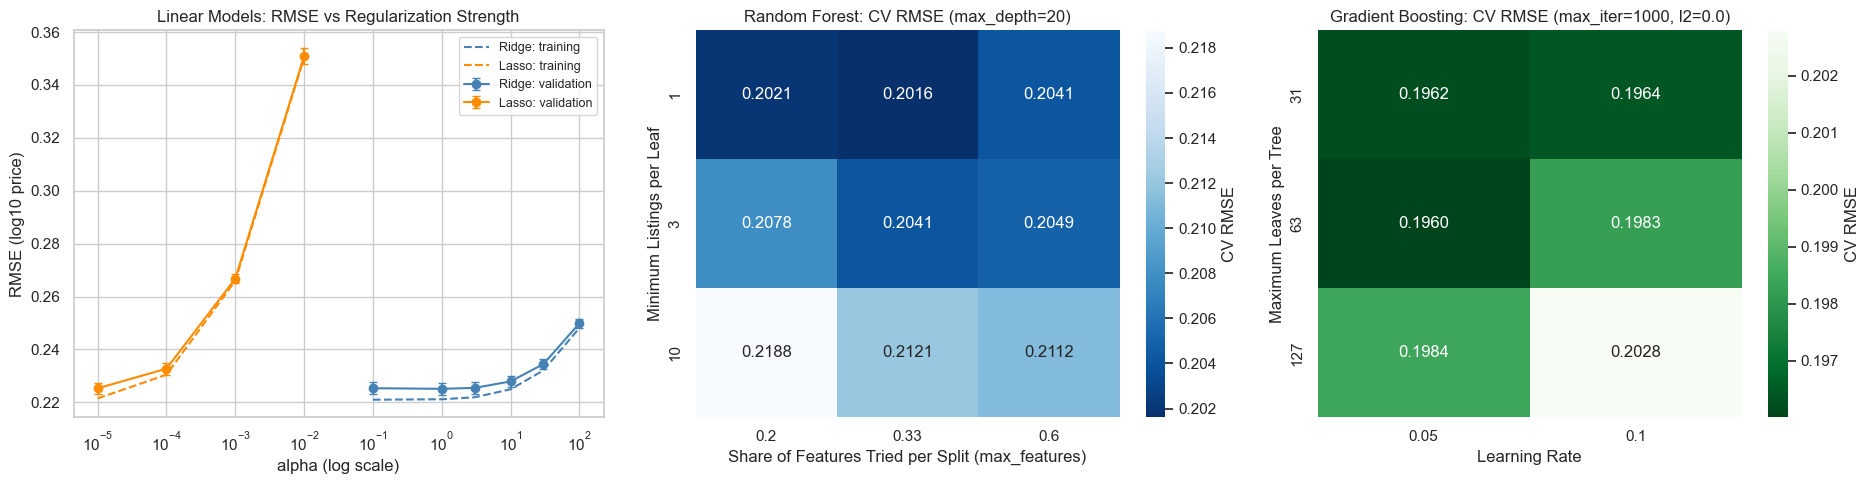

l2_regularization,learning_rate,max_iter,max_leaf_nodes,cv_rmse,cv_rmse_std,train_rmse
0.0000,0.0500,1000,63,0.1960,0.0017,0.1547
1.0000,0.0500,1000,63,0.1961,0.0018,0.1552
1.0000,0.1000,1000,31,0.1962,0.0020,0.1567
1.0000,0.0500,600,63,0.1962,0.0019,0.1640
0.0000,0.0500,1000,31,0.1962,0.0022,0.1679


In [5]:
def cv_table(search):
    """Grid search results as a tidy table (RMSE, lower is better)."""
    results = pd.DataFrame(search.cv_results_)
    params = pd.json_normalize(results["params"]).rename(columns=lambda c: c.replace("model__", ""))
    return params.assign(cv_rmse=-results["mean_test_score"], cv_rmse_std=results["std_test_score"],
                         train_rmse=-results["mean_train_score"])


fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Ridge and Lasso: validation curve over alpha
for model_name, color in [("Ridge", "steelblue"), ("Lasso", "darkorange")]:
    table = cv_table(grid_searches[model_name])
    axes[0].errorbar(table["alpha"], table["cv_rmse"], yerr=table["cv_rmse_std"], marker="o",
                     color=color, capsize=3, label=f"{model_name}: validation")
    axes[0].plot(table["alpha"], table["train_rmse"], linestyle="--", color=color, label=f"{model_name}: training")
axes[0].set_xscale("log")
axes[0].set_title("Linear Models: RMSE vs Regularization Strength")
axes[0].set_xlabel("alpha (log scale)")
axes[0].set_ylabel("RMSE (log10 price)")
axes[0].legend(fontsize=9)

# Random Forest: heatmap of min_samples_leaf x max_features (best depth)
rf_table = cv_table(grid_searches["Random Forest"])
best_depth = grid_searches["Random Forest"].best_params_["model__max_depth"]
rf_pivot = (rf_table[rf_table["max_depth"].isna() if best_depth is None else rf_table["max_depth"] == best_depth]
            .pivot(index="min_samples_leaf", columns="max_features", values="cv_rmse"))
sns.heatmap(rf_pivot, annot=True, fmt=".4f", cmap="Blues_r", cbar_kws={"label": "CV RMSE"}, ax=axes[1])
axes[1].set_title(f"Random Forest: CV RMSE (max_depth={best_depth})")
axes[1].set_xlabel("Share of Features Tried per Split (max_features)")
axes[1].set_ylabel("Minimum Listings per Leaf")

# Gradient boosting: heatmap of max_leaf_nodes x learning rate (best max_iter and l2)
gb_table = cv_table(grid_searches["Gradient Boosting"])
gb_best = grid_searches["Gradient Boosting"].best_params_
gb_pivot = (gb_table[(gb_table["max_iter"] == gb_best["model__max_iter"])
                     & (gb_table["l2_regularization"] == gb_best["model__l2_regularization"])]
            .pivot(index="max_leaf_nodes", columns="learning_rate", values="cv_rmse"))
sns.heatmap(gb_pivot, annot=True, fmt=".4f", cmap="Greens_r", cbar_kws={"label": "CV RMSE"}, ax=axes[2])
axes[2].set_title(f"Gradient Boosting: CV RMSE (max_iter={gb_best['model__max_iter']}, "
                  f"l2={gb_best['model__l2_regularization']})")
axes[2].set_xlabel("Learning Rate")
axes[2].set_ylabel("Maximum Leaves per Tree")

plt.tight_layout()
plt.show()

display(gb_table.sort_values("cv_rmse").head(5).style.format(precision=4).hide(axis="index"))

**Observation:** 
- **Ridge** is not very sensitive to `alpha` between 0.1 and 3 (best: 1); stronger regularization starts to hurt. **Lasso** does best with the *weakest* penalty (1e-5): stronger L1 penalties increase the error, and at its best setting Lasso performs the same as Ridge (CV RMSE 0.2253 vs 0.2251).
- **Random Forest** works best with fully grown leaves (minimum 1 listing per leaf), a third of the features tried per split and a depth limit of 20.
- **Gradient Boosting** works best with a lower learning rate (0.05), more trees (1,000) and medium-sized trees (63 leaves). 1,000 trees is the top of the grid, but the gain from 600 to 1,000 trees is tiny (CV RMSE 0.1962 to 0.1960), so a larger grid is unlikely to change the conclusions. The top five combinations are all within 0.0003 of each other, so the model is robust to these choices.
- **Overfitting check:** the linear models have almost no gap between training and validation error. The tree models fit the training data much more closely (e.g. Random Forest: 0.141 vs 0.202), which is expected for flexible models, but they still have the **lowest validation error**, so the extra flexibility generalizes.

## 5. Model Comparison on the Tuning Sample
Models are compared on their **cross-validated** scores from the tuning step, not on the test set, so the test set stays untouched for the final check.

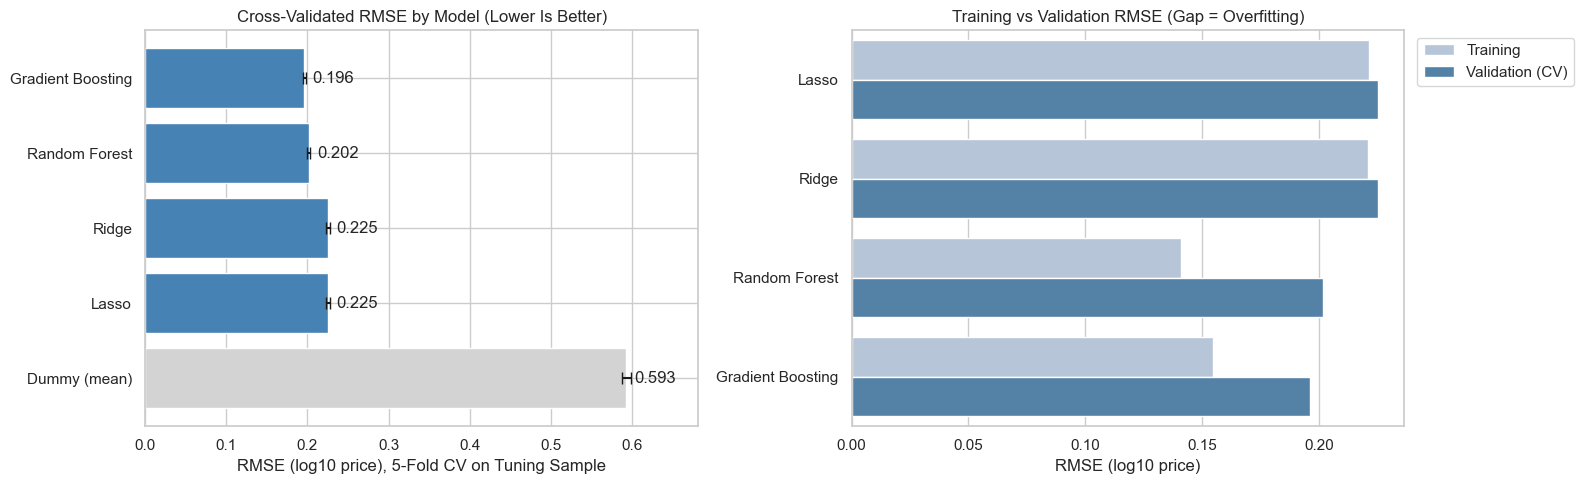

,CV RMSE (log10),CV RMSE std,Train RMSE (log10),Fit time per fold (s),Error factor
Model,,,,,
Gradient Boosting,0.1960,0.0017,0.1547,7.9,1.57x
Random Forest,0.2016,0.0017,0.1409,5.5,1.59x
Ridge,0.2251,0.0023,0.2212,0.4,1.68x
Lasso,0.2253,0.0021,0.2215,24.5,1.68x
Dummy (mean),0.5931,0.0056,0.5931,0.1,3.92x


In [6]:
comparison_rows = []
for model_name, search in grid_searches.items():
    best = search.best_index_
    results = search.cv_results_
    comparison_rows.append({
        "Model": model_name,
        "CV RMSE (log10)": -results["mean_test_score"][best],
        "CV RMSE std": results["std_test_score"][best],
        "Train RMSE (log10)": -results["mean_train_score"][best],
        "Fit time per fold (s)": results["mean_fit_time"][best],
    })
cv_comparison = pd.DataFrame(comparison_rows).set_index("Model").sort_values("CV RMSE (log10)", ascending=False)
cv_comparison["Error factor"] = 10 ** cv_comparison["CV RMSE (log10)"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(cv_comparison.index, cv_comparison["CV RMSE (log10)"], xerr=cv_comparison["CV RMSE std"],
             color=["lightgray"] + ["steelblue"] * (len(cv_comparison) - 1), capsize=4)
for i, value in enumerate(cv_comparison["CV RMSE (log10)"]):
    axes[0].text(value + 0.01, i, f"{value:.3f}", va="center")
axes[0].set_title("Cross-Validated RMSE by Model (Lower Is Better)")
axes[0].set_xlabel("RMSE (log10 price), 5-Fold CV on Tuning Sample")
axes[0].set_xlim(0, cv_comparison["CV RMSE (log10)"].max() * 1.15)

melted = cv_comparison[["Train RMSE (log10)", "CV RMSE (log10)"]].rename(
    columns={"Train RMSE (log10)": "Training", "CV RMSE (log10)": "Validation (CV)"}).drop(index="Dummy (mean)").reset_index().melt(
    id_vars="Model", var_name="Data", value_name="RMSE")
sns.barplot(data=melted, x="RMSE", y="Model", hue="Data", palette=["lightsteelblue", "steelblue"], ax=axes[1])
axes[1].set_title("Training vs Validation RMSE (Gap = Overfitting)")
axes[1].set_xlabel("RMSE (log10 price)")
axes[1].set_ylabel("")
axes[1].legend(title="", loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.show()

display(cv_comparison.sort_values("CV RMSE (log10)").style.format(
    {"CV RMSE (log10)": "{:.4f}", "CV RMSE std": "{:.4f}", "Train RMSE (log10)": "{:.4f}",
     "Fit time per fold (s)": "{:.1f}", "Error factor": "{:.2f}x"}))

**Observation:** All four real models beat the dummy benchmark by a wide margin (CV RMSE 0.59, i.e. typically off by a factor of almost 4). **Gradient Boosting has the lowest cross-validated RMSE (0.196, typical error factor 1.57x)**, followed by Random Forest (0.202). Ridge and Lasso are tied at 0.225. The fold-to-fold standard deviation is about 0.002, so the gap between the tree models and the linear models (about 0.03) is far larger than the noise, while the gap between the two tree models is small. The tree models likely gain from capturing **interactions** (for example, the value added by a gold case can differ between brands) and **non-linear effects** (age), which a linear model cannot represent. Training time is not a concern: on the tuning sample every model trains in under 25 seconds per fold (Lasso is the slowest).

## 6. Which Features Matter? Full-Training-Set Cross-Validation and Final Selection
This is the core of the research question. The tuned Ridge (best linear model), Random Forest and Gradient Boosting models are cross-validated (5 folds) on the **full training set** (208,000 listings) with each feature set from section 3. The difference between sets shows how much the brand and the model line each add.

This step also picks the final model. The tuning sample was only 40,000 listings, and tree models can gain more from extra data than linear ones (the results below confirm this: Gradient Boosting's CV RMSE drops from 0.196 to 0.185, while Ridge's stays at about 0.226), so the **final model is the one with the lowest cross-validated RMSE on the full training set with feature set C**. The test set is still not used for this choice.

In [7]:
best_params = {name: {k.replace("model__", ""): v for k, v in search.best_params_.items()}
               for name, search in grid_searches.items()}

ablation_rows = []
for model_name in ["Ridge", "Random Forest", "Gradient Boosting"]:
    for feature_set in FEATURE_SETS:
        start = time.time()
        scores = cross_validate(make_pipeline(model_name, feature_set, **best_params[model_name]),
                                train_df[feature_columns(feature_set)], train_df[TARGET], cv=cv_folds, n_jobs=-1,
                                scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
        ablation_rows.append({"Model": model_name, "Feature set": feature_set,
                              "CV RMSE (log10)": -scores["test_rmse"].mean(),
                              "CV RMSE std": scores["test_rmse"].std(),
                              "CV R²": scores["test_r2"].mean()})
        print(f"{model_name:<18} {feature_set:<16} CV RMSE {-scores['test_rmse'].mean():.4f} "
              f"R² {scores['test_r2'].mean():.3f} ({time.time() - start:.0f}s)")

ablation = pd.DataFrame(ablation_rows)

# Final model: lowest full-training-set CV RMSE with the complete feature set
full_set_results = ablation[ablation["Feature set"] == FEATURE_SET].set_index("Model")
selected_model_name = full_set_results["CV RMSE (log10)"].idxmin()
print(f"Selected model: {selected_model_name}")

Ridge              A: Attributes    CV RMSE 0.4847 R² 0.334 (1s)
Ridge              B: + Brand       CV RMSE 0.2825 R² 0.774 (2s)
Ridge              C: + Model line  CV RMSE 0.2258 R² 0.855 (3s)
Random Forest      A: Attributes    CV RMSE 0.4119 R² 0.519 (13s)
Random Forest      B: + Brand       CV RMSE 0.2231 R² 0.859 (18s)
Random Forest      C: + Model line  CV RMSE 0.1863 R² 0.902 (20s)
Gradient Boosting  A: Attributes    CV RMSE 0.4057 R² 0.533 (26s)
Gradient Boosting  B: + Brand       CV RMSE 0.2174 R² 0.866 (39s)
Gradient Boosting  C: + Model line  CV RMSE 0.1845 R² 0.903 (84s)
Selected model: Gradient Boosting


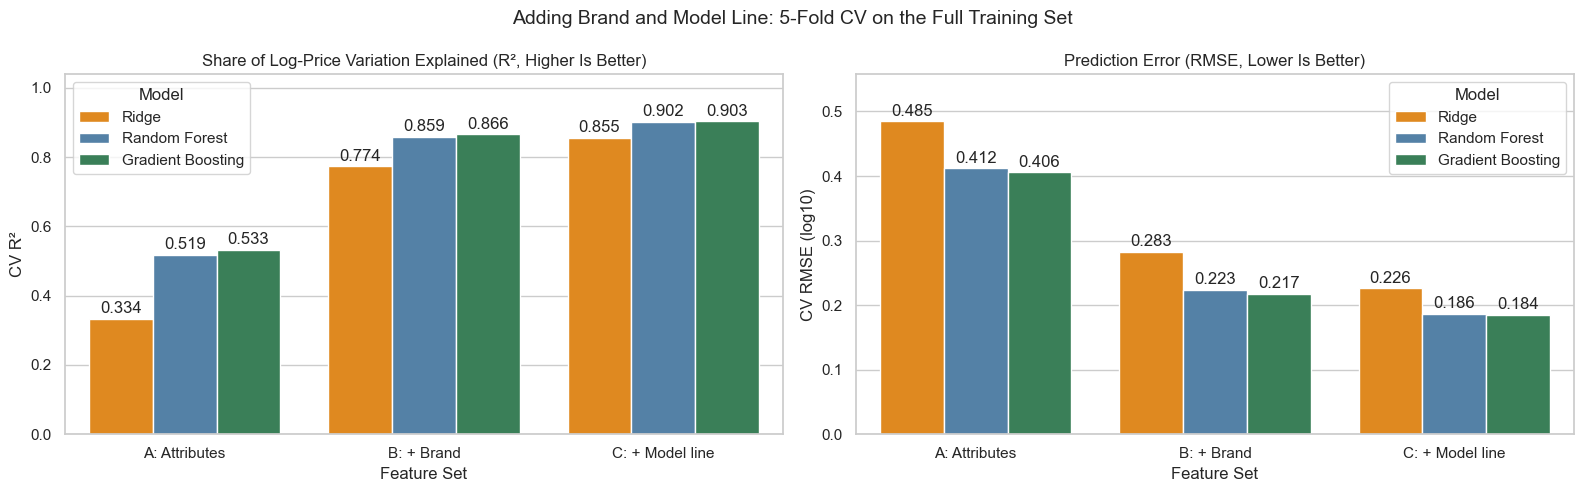

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric in zip(axes, ["CV R²", "CV RMSE (log10)"]):
    sns.barplot(data=ablation, x="Feature set", y=metric, hue="Model", palette=["darkorange", "steelblue", "seagreen"], ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=2)
    ax.set_xlabel("Feature Set")
    ax.set_ylabel(metric)
    ax.set_ylim(0, ablation[metric].max() * 1.15)
axes[0].set_title("Share of Log-Price Variation Explained (R², Higher Is Better)")
axes[1].set_title("Prediction Error (RMSE, Lower Is Better)")
plt.suptitle("Adding Brand and Model Line: 5-Fold CV on the Full Training Set", fontsize=14)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "feature_set_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

display(ablation.pivot(index="Feature set", columns="Model", values=["CV R²", "CV RMSE (log10)"])
        .style.format("{:.3f}"))

**Observation:** This answers the "which combination of features" part of the research question:
- **Attributes alone** (materials, movement, condition, size, age, complications) explain only about **half** of the variation in log price (Gradient Boosting R² 0.53; Ridge 0.33).
- **Adding the brand** is the biggest single jump: R² rises to **0.87** and the RMSE almost halves (0.406 to 0.217).
- **Adding the model line** brings a further, clear improvement: R² **0.90** and RMSE down another 15% (0.217 to 0.184). The model line adds the most for the linear model (R² 0.774 to 0.855), likely because it lets Ridge price each model separately without needing interactions.
- **Gradient Boosting and Random Forest are almost tied** on the full training set (RMSE 0.1845 vs 0.1863); Gradient Boosting stays slightly ahead, consistent with the tuning sample, and is **selected as the final model**.

**Takeaway:** price is driven first by *who made the watch*, then by *which model it is*, and then by its physical attributes and condition. Each layer adds real predictive value.

## 7. Hold-Out Test Set: Final Check
Each tuned model is re-trained on the **full training set** (208,000 listings) and evaluated once on the 52,000 test listings it has never seen.

In [9]:
final_models, test_rows = {}, []
for model_name in param_grids:
    start = time.time()
    pipeline = make_pipeline(model_name, FEATURE_SET, **best_params[model_name]).fit(X_train, y_train)
    final_models[model_name] = pipeline
    test_rows.append({"Model": model_name, **regression_metrics(y_test, pipeline.predict(X_test)),
                      "Fit time (s)": time.time() - start})

test_results = pd.DataFrame(test_rows).set_index("Model").sort_values("RMSE (log10)")
test_results["Error factor"] = 10 ** test_results["RMSE (log10)"]
display(test_results.style.format({**metric_formats, "Fit time (s)": "{:.0f}"})
        .highlight_min(subset=["RMSE (log10)", "MdAPE"], color="#c6efce")
        .highlight_max(subset=["R² (log)", "Within ±25%"], color="#c6efce"))

,RMSE (log10),R² (log),MAE (log10),MdAPE,Within ±25%,Median abs error (USD),Fit time (s),Error factor
Model,,,,,,,,
Gradient Boosting,0.184,0.905,0.126,20.1%,58.5%,"$1,173",24,1.53x
Random Forest,0.184,0.904,0.125,19.6%,59.2%,"$1,149",6,1.53x
Ridge,0.225,0.857,0.159,26.3%,48.0%,"$1,520",6,1.68x
Lasso,0.226,0.856,0.160,26.5%,47.8%,"$1,528",350,1.68x
Dummy (mean),0.595,-0.000,0.460,69.5%,17.0%,"$4,830",1,3.93x


**Interpretation:** 
- **The test results match the cross-validation results** (Gradient Boosting test RMSE 0.184 vs 0.1845 in CV), so there is no sign of overfitting to the tuning process, and similar accuracy can be expected for new listings from the same source.
- **Gradient Boosting: R² = 0.905, RMSE = 0.184 (typical error factor 1.53x), median error 20%, and 58.5% of predictions within ±25%** of the listed price. Random Forest is effectively tied (median error 19.6%), so either would serve; the choice was made before looking at the test set.
- Compared with **Ridge** (R² 0.857, median error 26%) the tree models cut the typical percentage error by about a quarter, and compared with the **dummy benchmark** (median error 70%) by more than two thirds.
- In dollars, the typical prediction is about **USD 1,170 away** from the listed price, against a median test price of about USD 6,800.

## 8. Saving the Selected Model
The selected pipeline (preprocessing + model, trained on the full training set; chosen in section 6) and the test-set results are saved for Notebook 3.

In [10]:
joblib.dump(final_models[selected_model_name], MODELS_DIR / "price_model_pipeline.joblib", compress=3)
test_results.to_csv(MODELS_DIR / "test_results.csv")
with open(MODELS_DIR / "model_settings.json", "w") as settings_file:
    json.dump({"selected_model": selected_model_name, "feature_set": FEATURE_SET,
               "features": feature_columns(FEATURE_SET), "target": TARGET, "random_state": RANDOM_STATE,
               "test_size": 0.2, "best_params": best_params}, settings_file, indent=2, default=str)

size_mb = (MODELS_DIR / "price_model_pipeline.joblib").stat().st_size / 1e6
print(f"Saved {selected_model_name} pipeline ({size_mb:.1f} MB), test results and settings to {MODELS_DIR}/")

Saved Gradient Boosting pipeline (3.3 MB), test results and settings to models/


## 9. Summary
1. **Five model types** were tuned with 5-fold cross-validated grid search on a 40,000-listing sample; the three best were then cross-validated on the full 208,000-listing training set.
2. **Primary metric: RMSE on log10 price**, because it measures relative error and penalizes large mispricings; R², median % error and the share within ±25% make the results easy to read.
3. **Gradient Boosting is the final model**: test R² 0.905, RMSE 0.184, median error 20%, a large improvement over Ridge (median error 26%) and the dummy benchmark (70%). Random Forest is a close second.
4. **Feature-set comparison:** attributes (movement, case & bracelet material, condition, gender, case size, age, approximate-year flag, 8 text flags (complications, diamonds, limited edition) alone explain about half of the price variation, adding the brand raises this to 87%, and adding the model line to 90%. Brand and model line are the most valuable information for pricing a watch.

**Next:** [Notebook 3](03_model_evaluation_and_insights.ipynb) looks inside the selected model: where it makes mistakes, which features drive its predictions and how much specific features are worth in dollars.